**Image Check**



0. Pengaturan

In [ ]:
import os, sys, json, platform
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import cv2
import matplotlib.pyplot as plt

# ===== Sumber gambar =====
USE_UPLOAD      = True    # True = tampilkan tombol upload (khusus Colab)
USE_DEMO        = False   # True = pakai gambar sintetis, bukan gambar Anda
FOLDER          = "."     # folder yang dipindai, mis. "/content/drive/MyDrive/imagecheck"
RECURSIVE       = False   # True = ikut cari di subfolder
PILIH           = None    # None = gambar valid terbaru | nomor urut | sebagian nama file
EXTENSIONS      = (".png", ".jpg", ".jpeg", ".bmp", ".webp", ".tif", ".tiff")
ALPHA_BG        = 255     # latar untuk PNG transparan: 255 = putih, 30 = gelap (untuk logo putih)

# ===== Opsi tampilan =====
RUN_EXPLORATION = True    # False = lewati bagian eksplorasi (bagian 2)

@dataclass
class Config:
    max_side: int = 640           # sisi terpanjang saat dianalisis
    min_side_px: int = 300        # di bawah ini dianggap resolusi rendah
    dark_mean: float = 65         # rata-rata gray di bawah ini = gelap
    bright_mean: float = 200      # rata-rata gray di atas ini = terang
    dark_fraction: float = 0.30   # porsi piksel sangat gelap (<20) yang dianggap tinggi
    bright_fraction: float = 0.30 # porsi piksel sangat terang (>235) yang dianggap tinggi
    min_contrast: float = 20.0    # selisih persentil 1-99; di bawahnya skor ketajaman tidak andal
    noise_max: float = 6.0        # estimasi sigma noise; di atasnya skor ketajaman tidak andal
    roi_min_pixels: int = 500     # minimal piksel objek agar analisis dibatasi ke objek

CFG = Config()
OUT = Path("imagecheck_outputs")
OUT.mkdir(exist_ok=True)

print("Python", sys.version.split()[0], "| OpenCV", cv2.__version__, "| NumPy", np.__version__)

def show_panels(items, ncols=3, figsize=(15, 5)):
    """items: list of (judul, gambar, cmap). Gambar BGR harus sudah dikonversi ke RGB."""
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize[0], figsize[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, (title, im, cmap) in zip(axes, items):
        ax.imshow(im, cmap=cmap if im.ndim == 2 else None)
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

def to_json(obj):
    return json.dumps(obj, indent=2, ensure_ascii=False,
                      default=lambda o: o.item() if hasattr(o, "item") else str(o))

Python 3.13.18 | OpenCV 5.0.0 | NumPy 2.1.3


1. Sumber gambar

Sel ini memindai folder, menampilkan semua gambar beserta statusnya (terbaca atau tidak), lalu memilih satu.

In [ ]:
if USE_UPLOAD:
    from google.colab import files
    _up = files.upload()
    print("Diupload:", list(_up))

def scan_images(folder=FOLDER, exts=EXTENSIONS, recursive=RECURSIVE):
    base = Path(folder)
    if not base.is_dir():
        raise FileNotFoundError(f"Folder tidak ditemukan: {base.resolve()}")
    rows = []
    for p in sorted(base.rglob("*") if recursive else base.glob("*")):
        rel = p.relative_to(base).parts
        if not p.is_file() or p.suffix.lower() not in exts:
            continue
        if any(part.startswith(".") for part in rel):   # lewati ._* dan folder tersembunyi
            continue
        if rel[0] == OUT.name:                          # lewati folder hasil sendiri
            continue
        img = cv2.imread(str(p), cv2.IMREAD_UNCHANGED)
        rows.append({"path": p, "size": p.stat().st_size, "mtime": p.stat().st_mtime,
                     "ok": img is not None, "shape": None if img is None else img.shape})
    return rows

def pick_image(rows, pilih=PILIH):
    if not rows:
        raise RuntimeError("Tidak ada file gambar di folder ini. Upload gambar aslinya, "
                           "atau set USE_DEMO = True untuk mencoba dengan gambar sintetis.")
    for i, r in enumerate(rows):
        status = f"terbaca {r['shape']}" if r["ok"] else "TIDAK terbaca (rusak / bukan gambar)"
        print(f"[{i}] {str(r['path']):50} {r['size']:>9} bytes  {status}")
    valid = [r for r in rows if r["ok"]]
    if not valid:
        raise RuntimeError("Ada file gambar, tetapi tidak satu pun yang bisa dibaca.")
    if pilih is None:
        chosen = max(valid, key=lambda r: r["mtime"])
    elif isinstance(pilih, int):
        chosen = rows[pilih]
    else:
        cocok = [r for r in valid if pilih.lower() in r["path"].name.lower()]
        if not cocok:
            raise ValueError(f"Tidak ada gambar valid yang namanya mengandung '{pilih}'.")
        chosen = cocok[0]
    if not chosen["ok"]:
        raise ValueError(f"File pilihan tidak bisa dibaca: {chosen['path']}")
    return str(chosen["path"])

if USE_DEMO:
    rows, USER_IMAGE_PATH = [], None
    print("Mode DEMO: memakai gambar sintetis.")
else:
    rows = scan_images()
    USER_IMAGE_PATH = pick_image(rows)
    print("\nDipakai:", USER_IMAGE_PATH)

Saving veggie.png to veggie.png
Diupload: ['veggie.png']
[0] veggie.png                                            216872 bytes  terbaca (315, 479, 4)

Dipakai: veggie.png


Ukuran (tinggi, lebar): (315, 479)
PNG transparan terdeteksi: objek = 67.9% dari piksel, latar digabung ke nilai 255


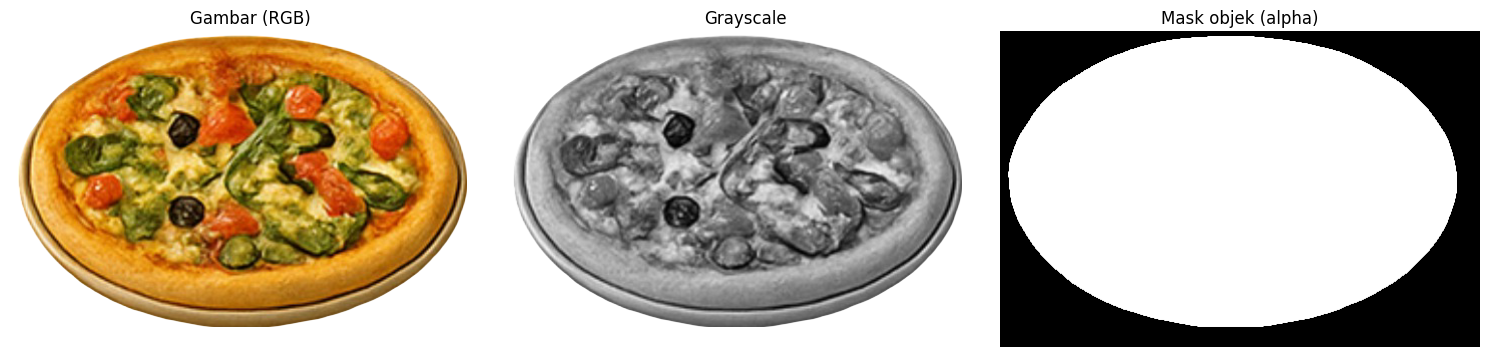

In [ ]:
def make_demo(seed=7):
    """Gambar sintetis (kotak kemasan + teks) untuk uji metrik. Bukan foto nyata."""
    rng = np.random.default_rng(seed)
    im = np.full((360, 480, 3), 225, np.uint8)
    color = tuple(int(x) for x in rng.integers(40, 160, 3))
    cv2.rectangle(im, (100, 35), (380, 325), color, -1)
    cv2.rectangle(im, (125, 90), (355, 265), (245, 245, 245), -1)
    cv2.putText(im, "PRODUCT", (140, 130), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (30, 30, 30), 2, cv2.LINE_AA)
    for _ in range(12):
        x, y = int(rng.integers(140, 340)), int(rng.integers(190, 250))
        cv2.circle(im, (x, y), 4, color, -1)
    return im

def load_image(path, bg=ALPHA_BG):
    """Baca gambar 8-bit. PNG transparan digabung ke latar `bg`.
    Mengembalikan (BGR uint8, mask objek bool atau None)."""
    if not Path(path).exists():
        raise FileNotFoundError(f"File tidak ditemukan: {path}")
    img = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if img is None:
        raise ValueError(f"File ada tapi gagal dibaca: {path} (rusak atau bukan gambar valid).")
    if img.dtype != np.uint8:
        raise ValueError("Hanya mendukung gambar 8-bit per channel.")
    if img.ndim == 2:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    mask = None
    if img.shape[2] == 4:
        a = img[..., 3:4].astype(np.float32) / 255
        mask = img[..., 3] > 127
        img = (img[..., :3] * a + bg * (1 - a)).astype(np.uint8)
    return img, mask

if USE_DEMO:
    bgr, mask = make_demo(), None
else:
    bgr, mask = load_image(USER_IMAGE_PATH)

rgb  = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
h, w = bgr.shape[:2]
print("Ukuran (tinggi, lebar):", (h, w))
if mask is not None:
    print(f"PNG transparan terdeteksi: objek = {mask.mean():.1%} dari piksel, latar digabung ke nilai {ALPHA_BG}")

panels = [("Gambar (RGB)", rgb, None), ("Grayscale", gray, "gray")]
if mask is not None:
    panels.append(("Mask objek (alpha)", mask.astype(np.uint8) * 255, "gray"))
show_panels(panels, ncols=len(panels), figsize=(5 * len(panels), 5))

2. Eksplorasi pengolahan citra

Bagian ini bersifat pembelajaran: Filter, spektrum FFT, pyramid, tepi, dan fitur ORB. Hasilnya tidak **masuk** ke laporan kualitas.

Level pyramid: [(315, 479), (158, 240), (79, 120), (40, 60)] | galat rekonstruksi maks = 0.00e+00
Piksel tepi: 16255 | keypoint ORB: 1000 (mencapai batas, jumlahnya tidak informatif)


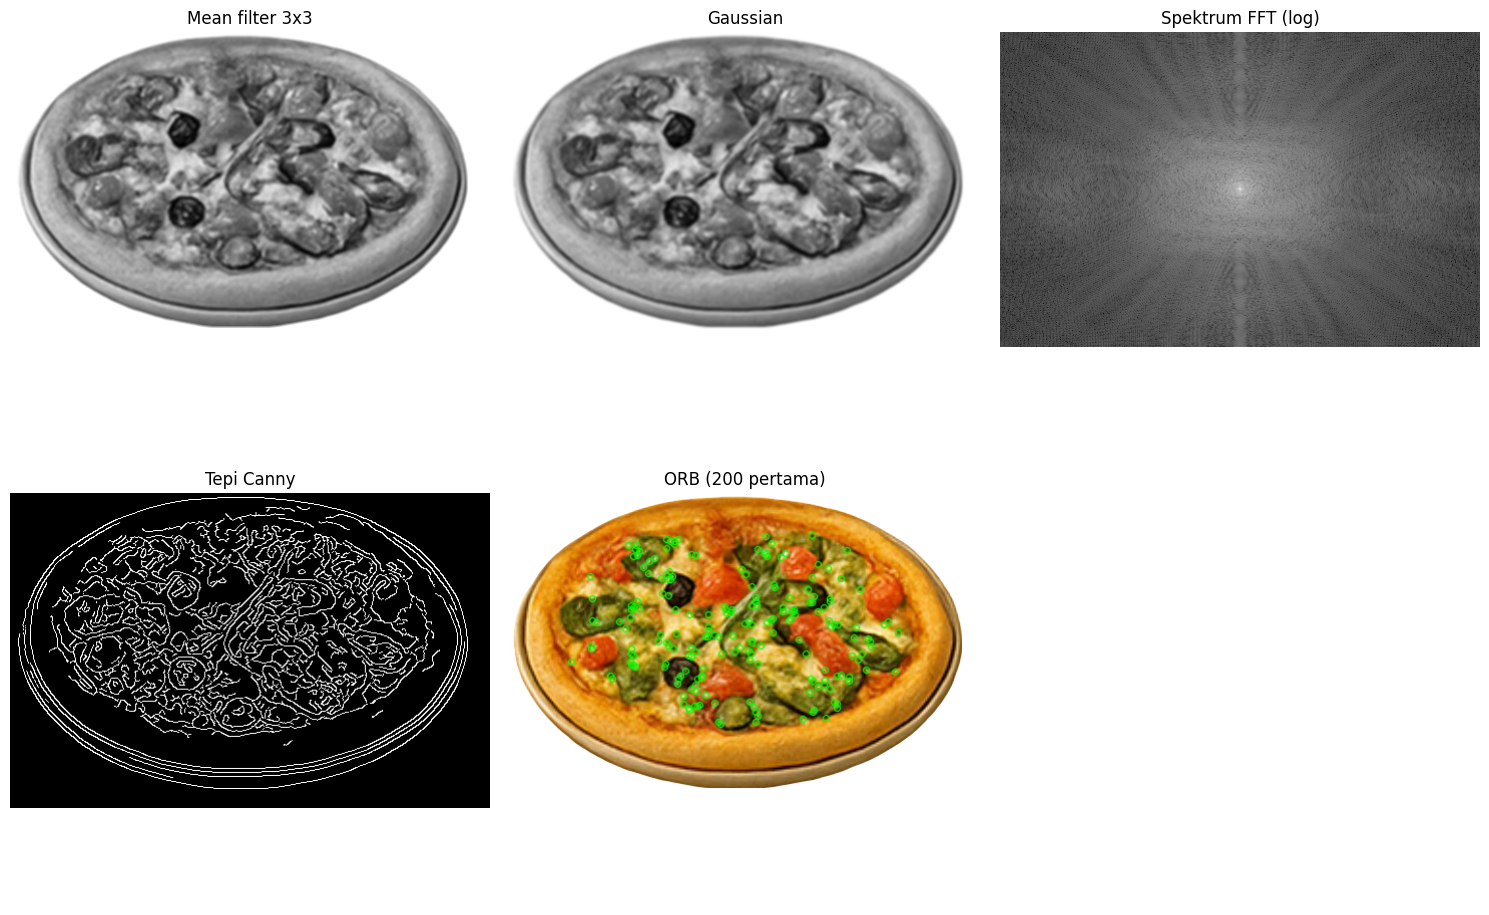

In [ ]:
edges = None
if RUN_EXPLORATION:
    # Mean filter 3x3 dan Gaussian
    mean_img  = cv2.filter2D(gray, -1, np.ones((3, 3), np.float32) / 9)
    gauss_img = cv2.GaussianBlur(gray, (5, 5), 1.2)

    # Spektrum FFT (skala log)
    spec = np.fft.fftshift(np.fft.fft2(gray.astype(np.float32)))
    fft_vis = np.log1p(np.abs(spec))

    # Laplacian pyramid + uji rekonstruksi (sanity check, bukan bukti kualitas)
    g0 = gray.astype(np.float32)
    gp = [g0]
    for _ in range(3):
        gp.append(cv2.pyrDown(gp[-1]))
    lp = []
    for i in range(3):
        up = cv2.pyrUp(gp[i + 1], dstsize=(gp[i].shape[1], gp[i].shape[0]))
        lp.append(gp[i] - up)
    rec = gp[-1]
    for i in range(2, -1, -1):
        rec = cv2.pyrUp(rec, dstsize=(lp[i].shape[1], lp[i].shape[0])) + lp[i]
    rec_err = float(np.max(np.abs(rec - g0)))
    print(f"Level pyramid: {[g.shape for g in gp]} | galat rekonstruksi maks = {rec_err:.2e}")
    assert rec_err < 1e-3

    # Tepi (Canny) dan fitur ORB
    edges = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 1.2), 60, 120)
    ORB_MAX = 1000
    orb = cv2.ORB_create(nfeatures=ORB_MAX)
    kps = orb.detect(gray, mask.astype(np.uint8) * 255 if mask is not None else None)
    note = " (mencapai batas, jumlahnya tidak informatif)" if len(kps) >= ORB_MAX else ""
    print(f"Piksel tepi: {np.count_nonzero(edges)} | keypoint ORB: {len(kps)}{note}")
    marked = cv2.drawKeypoints(bgr, kps[:200], None, color=(0, 255, 0))

    show_panels([("Mean filter 3x3", mean_img, "gray"), ("Gaussian", gauss_img, "gray"),
                 ("Spektrum FFT (log)", fft_vis, "gray"), ("Tepi Canny", edges, "gray"),
                 ("ORB (200 pertama)", cv2.cvtColor(marked, cv2.COLOR_BGR2RGB), None)], ncols=3, figsize=(15, 5))
else:
    print("Eksplorasi dilewati.")

## 3. Metrik kualitas

| Metrik | Arti | Catatan |
|---|---|---|
| `sharpness_norm` | Varians Laplacian dibagi kontras² | Tahan terhadap gambar gelap/terang |
| `laplacian_variance` | Varians Laplacian mentah | Hanya untuk perbandingan, **bergantung kecerahan** |
| `noise_sigma` | Estimasi sigma noise (metode Immerkaer) | Heuristik; tekstur halus bisa terbaca sebagai noise |
| `contrast` | Selisih persentil 1 dan 99 gray | Terlalu kecil = skor ketajaman tidak andal |
| `dark_fraction`, `bright_fraction` | Porsi piksel < 20 dan > 235 | |

Bila gambar punya alpha, statistik dihitung **hanya pada area objek** (mask dikikis 5 px agar tepi siluet tidak mendominasi).

In [ ]:
_NOISE_KERNEL = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)

def _prepare(image, mask, cfg):
    ih, iw = image.shape[:2]
    scale = min(1.0, cfg.max_side / max(ih, iw))
    if scale < 1.0:
        size = (max(1, round(iw * scale)), max(1, round(ih * scale)))
        image = cv2.resize(image, size, interpolation=cv2.INTER_AREA)
        if mask is not None:
            mask = cv2.resize(mask.astype(np.uint8), size, interpolation=cv2.INTER_NEAREST).astype(bool)
    return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY), mask, (ih, iw)

def _roi(mask, shape, cfg):
    if mask is None:
        return np.ones(shape, bool), False
    roi = cv2.erode(mask.astype(np.uint8), np.ones((5, 5), np.uint8)).astype(bool)
    if roi.sum() < cfg.roi_min_pixels:
        return np.ones(shape, bool), False
    return roi, True

def measure(image, mask=None, cfg=CFG):
    if not isinstance(image, np.ndarray) or image.dtype != np.uint8 or image.ndim != 3 or image.shape[2] != 3:
        raise ValueError("Gambar harus BGR uint8 dengan 3 channel (pakai load_image).")
    if min(image.shape[:2]) < 8:
        raise ValueError("Gambar terlalu kecil untuk dianalisis (minimal 8 px).")
    gray, mask, (ih, iw) = _prepare(image, mask, cfg)
    g = gray.astype(np.float32)
    roi, roi_used = _roi(mask, g.shape, cfg)

    lap = cv2.Laplacian(g, cv2.CV_32F)
    vals = g[roi]
    p1, p99 = np.percentile(vals, [1, 99])
    contrast = max(float(p99 - p1), 1.0)
    lap_var = float(lap[roi].var())

    resid = cv2.filter2D(g, -1, _NOISE_KERNEL)
    roi_n = roi.copy()
    roi_n[[0, -1], :] = False
    roi_n[:, [0, -1]] = False
    if roi_n.sum() == 0:
        roi_n = np.ones_like(roi)
    noise = float(np.sqrt(np.pi / 2) / 6 * np.mean(np.abs(resid[roi_n])))

    return {
        "original_height": int(ih), "original_width": int(iw),
        "analyzed_height": int(g.shape[0]), "analyzed_width": int(g.shape[1]),
        "roi_used": bool(roi_used), "roi_fraction": float(roi.mean()),
        "mean_gray": float(vals.mean()),
        "dark_fraction": float((vals < 20).mean()),
        "bright_fraction": float((vals > 235).mean()),
        "contrast": contrast,
        "laplacian_variance": lap_var,
        "sharpness_norm": lap_var / contrast ** 2,
        "noise_sigma": noise,
    }

def assess(image, mask=None, sharp_threshold=None, cfg=CFG):
    m = measure(image, mask, cfg)
    tips, reliable = [], True
    if min(m["original_height"], m["original_width"]) < cfg.min_side_px:
        tips.append(f"Resolusi rendah (sisi terpendek < {cfg.min_side_px}px).")
    if m["mean_gray"] < cfg.dark_mean:
        tips.append("Rata-rata kecerahan rendah: tambah pencahayaan atau cek exposure.")
    elif m["mean_gray"] > cfg.bright_mean:
        tips.append("Rata-rata kecerahan tinggi: kurangi exposure atau cek area terlalu terang.")
    if m["dark_fraction"] > cfg.dark_fraction:
        tips.append(f"{m['dark_fraction']:.0%} piksel sangat gelap: cek bayangan, latar gelap, atau transparansi.")
    if m["bright_fraction"] > cfg.bright_fraction:
        tips.append(f"{m['bright_fraction']:.0%} piksel sangat terang: bisa jadi latar putih atau area overexposed.")
    if m["contrast"] < cfg.min_contrast:
        reliable = False
        tips.append("Kontras rendah: skor ketajaman tidak andal.")
    if m["noise_sigma"] > cfg.noise_max:
        reliable = False
        tips.append("Estimasi noise tinggi: skor ketajaman tidak andal (noise terbaca sebagai detail).")
    if not reliable:
        tips.append("Ketajaman tidak diklasifikasikan.")
    elif sharp_threshold is None:
        tips.append("Skor ketajaman dihitung, tetapi belum diklasifikasikan: butuh threshold dari foto nyata berlabel.")
    elif m["sharpness_norm"] < sharp_threshold:
        tips.append("Indikasi buram / detail rendah (di bawah threshold).")
    else:
        tips.append("Skor ketajaman di atas threshold.")
    return {"metrics": m, "sharp_threshold": sharp_threshold,
            "sharpness_reliable": reliable, "suggestions": tips}

result = assess(bgr, mask)
print(to_json(result))

{
  "metrics": {
    "original_height": 315,
    "original_width": 479,
    "analyzed_height": 315,
    "analyzed_width": 479,
    "roi_used": true,
    "roi_fraction": 0.6591377539185472,
    "mean_gray": 130.38021850585938,
    "dark_fraction": 0.008868421581836828,
    "bright_fraction": 0.0005329096868904217,
    "contrast": 196.0,
    "laplacian_variance": 302.3760070800781,
    "sharpness_norm": 0.007871095561226523,
    "noise_sigma": 0.989822096218159
  },
  "sharp_threshold": null,
  "sharpness_reliable": true,
  "suggestions": [
    "Skor ketajaman dihitung, tetapi belum diklasifikasikan: butuh threshold dari foto nyata berlabel."
  ]
}


Peta Ketajaman lokal

Gambar dibagi menjadi grid, lalu skor dihitung per blok (dinormalisasi dengan kontras global). Berguna untuk membedakan "seluruh gambar buram" dari "hanya sebagian buram" (misalnya latar sengaja blur). Blok tanpa cukup piksel objek ditampilkan kosong.

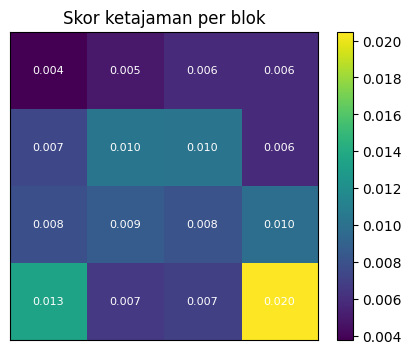

Blok valid: 16/16 | median=0.0076 | min=0.0038 | maks=0.0205


In [ ]:
def local_sharpness_map(image, mask=None, grid=(4, 4), cfg=CFG, min_pixels=50):
    gray_s, mask_s, _ = _prepare(image, mask, cfg)
    g = gray_s.astype(np.float32)
    roi, _ = _roi(mask_s, g.shape, cfg)
    p1, p99 = np.percentile(g[roi], [1, 99])
    contrast = max(float(p99 - p1), 1.0)
    lap = cv2.Laplacian(g, cv2.CV_32F)
    H, W = g.shape
    out = np.full(grid, np.nan)
    for i in range(grid[0]):
        for j in range(grid[1]):
            ys = slice(i * H // grid[0], (i + 1) * H // grid[0])
            xs = slice(j * W // grid[1], (j + 1) * W // grid[1])
            sel = roi[ys, xs]
            if sel.sum() >= min_pixels:
                out[i, j] = lap[ys, xs][sel].var() / contrast ** 2
    return out

lmap = local_sharpness_map(bgr, mask)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(np.ma.masked_invalid(lmap), cmap="viridis")
for (i, j), v in np.ndenumerate(lmap):
    if not np.isnan(v):
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", color="w", fontsize=8)
ax.set_title("Skor ketajaman per blok"); ax.set_xticks([]); ax.set_yticks([])
plt.colorbar(im, ax=ax, fraction=0.046); plt.show()
valid_blocks = lmap[~np.isnan(lmap)]
if valid_blocks.size:
    print(f"Blok valid: {valid_blocks.size}/{lmap.size} | median={np.median(valid_blocks):.4f} "
          f"| min={valid_blocks.min():.4f} | maks={valid_blocks.max():.4f}")

4. Uji ketahanan metrik

Gambar diberi gangguan yang terkontrol: **blur**, **blur + noise**, dan **digelapkan**. Metrik yang baik harus memenuhi:
- gambar gelap tapi tajam tetap mendapat skor ternormalisasi yang mirip aslinya,
- blur menurunkan skor,
- noise terdeteksi lewat `noise_sigma`.

Pemeriksaan keras (`assert`) dijalankan pada gambar demo yang deterministik. Gambar Anda hanya ditampilkan sebagai tabel, karena hasilnya bergantung pada isi gambar.

In [ ]:
def make_variants(img, seed=42):
    rng = np.random.default_rng(seed)
    blurred = cv2.GaussianBlur(img, (0, 0), sigmaX=3)
    noisy = np.clip(blurred.astype(float) + rng.normal(0, 18, blurred.shape), 0, 255).astype(np.uint8)
    dark = (img.astype(float) * 0.3).astype(np.uint8)
    return {"asli": img, "blur": blurred, "blur+noise": noisy, "gelap": dark}

def print_table(variants, mask=None):
    print(f"{'varian':12} {'mean':>7} {'LapVar':>10} {'norm':>9} {'noise':>7}")
    for name, im in variants.items():
        m = measure(im, mask)
        print(f"{name:12} {m['mean_gray']:7.1f} {m['laplacian_variance']:10.2f} "
              f"{m['sharpness_norm']:9.4f} {m['noise_sigma']:7.2f}")

print("== Gambar Anda ==" if not USE_DEMO else "== Gambar demo ==")
print_table(make_variants(bgr), mask)

print("\n== Pemeriksaan pada gambar demo (deterministik) ==")
demo_vars = make_variants(make_demo(7))
print_table(demo_vars)
md_ = {k: measure(v) for k, v in demo_vars.items()}
checks = [
    ("gelap: skor ternormalisasi mirip aslinya (selisih < 15%)",
     abs(md_["gelap"]["sharpness_norm"] / md_["asli"]["sharpness_norm"] - 1) < 0.15),
    ("blur: skor turun lebih dari 10x",
     md_["blur"]["sharpness_norm"] < md_["asli"]["sharpness_norm"] / 10),
    ("noise terdeteksi pada blur+noise (sigma > noise_max)",
     md_["blur+noise"]["noise_sigma"] > CFG.noise_max),
    ("noise tidak terdeteksi pada gambar asli",
     md_["asli"]["noise_sigma"] < CFG.noise_max),
]
for desc, ok in checks:
    print(("LOLOS  " if ok else "GAGAL  ") + desc)
assert all(ok for _, ok in checks), "Ada pemeriksaan metrik yang gagal."

== Gambar Anda ==
varian          mean     LapVar      norm   noise
asli           130.4     302.38    0.0079    0.99
blur           130.7       5.87    0.0003    0.33
blur+noise     130.3    2862.69    0.1147   11.96
gelap           38.7      29.04    0.0085    0.44

== Pemeriksaan pada gambar demo (deterministik) ==
varian          mean     LapVar      norm   noise
asli           203.4     587.17    0.0382    0.29
blur           203.5       1.48    0.0001    0.02
blur+noise     202.3    2579.28    0.1116   11.30
gelap           60.6      52.38    0.0383    0.09
LOLOS  gelap: skor ternormalisasi mirip aslinya (selisih < 15%)
LOLOS  blur: skor turun lebih dari 10x
LOLOS  noise terdeteksi pada blur+noise (sigma > noise_max)
LOLOS  noise tidak terdeteksi pada gambar asli


5. Kalibrasi threshold (sintetis)

Threshold dicari dari gambar sintetis, lalu diuji pada objek lain yang **tidak tumpang tindih**. Variasi data: gambar tajam (asli dan digelapkan) dan gambar buram (σ = 2 dan 3).

**Peringatan:** ini hanya bukti bahwa metrik memisahkan blur dari gelap pada data buatan. Threshold ini **tidak dipakai** untuk menilai gambar Anda. Threshold untuk foto nyata harus dikalibrasi dari foto nyata berlabel.

In [ ]:
def control_rows(seeds):
    rows_ = []
    for seed in seeds:
        base = make_demo(seed)
        sharp = [base, (base.astype(float) * 0.5).astype(np.uint8)]
        blurry = [cv2.GaussianBlur(base, (0, 0), sigmaX=s) for s in (2, 3)]
        for im in sharp:
            rows_.append({"object_id": seed, "label": 0, "score": measure(im)["sharpness_norm"]})
        for im in blurry:
            rows_.append({"object_id": seed, "label": 1, "score": measure(im)["sharpness_norm"]})
    return rows_

def prf(rows_, thr):
    tp = sum(1 for r in rows_ if r["label"] == 1 and r["score"] < thr)
    fp = sum(1 for r in rows_ if r["label"] == 0 and r["score"] < thr)
    fn = sum(1 for r in rows_ if r["label"] == 1 and r["score"] >= thr)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    return {"precision": p, "recall": r, "f1": f1, "tp": tp, "fp": fp, "fn": fn}

calibration = control_rows(range(10, 16))
test_set    = control_rows(range(20, 28))
assert not ({r["object_id"] for r in calibration} & {r["object_id"] for r in test_set})

sc = sorted({r["score"] for r in calibration})
candidates = [sc[0] * 0.5] + [float(np.sqrt(a * b)) for a, b in zip(sc, sc[1:])] + [sc[-1] * 2]
f1s = [prf(calibration, c)["f1"] for c in candidates]
tied = [c for c, f in zip(candidates, f1s) if f == max(f1s)]
threshold = tied[len(tied) // 2]

max_blur  = max(r["score"] for r in calibration if r["label"] == 1)
min_sharp = min(r["score"] for r in calibration if r["label"] == 0)
gap_ratio = min_sharp / max_blur if max_blur > 0 else float("inf")

cal_eval, test_eval = prf(calibration, threshold), prf(test_set, threshold)
print(f"Threshold sintetis (sharpness_norm) = {threshold:.5f}")
print(f"Rasio pemisah (skor tajam terendah / skor buram tertinggi) = {gap_ratio:.1f}x")
print("Kalibrasi:", {k: round(v, 3) for k, v in cal_eval.items()})
print("Tes      :", {k: round(v, 3) for k, v in test_eval.items()})
print("\nCatatan: hasil sempurna pada data sintetis yang mudah dipisah BUKAN bukti performa pada foto nyata.")

Threshold sintetis (sharpness_norm) = 0.00391
Rasio pemisah (skor tajam terendah / skor buram tertinggi) = 81.6x
Kalibrasi: {'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'tp': 12, 'fp': 0, 'fn': 0}
Tes      : {'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'tp': 16, 'fp': 0, 'fn': 0}

Catatan: hasil sempurna pada data sintetis yang mudah dipisah BUKAN bukti performa pada foto nyata.


6. Laporan dan mode batch

- **Laporan** untuk gambar terpilih disimpan sebagai JSON. Hasil kalibrasi sintetis ditaruh di bagian terpisah dan diberi label.
- **Batch**: semua gambar valid di folder diproses dan disimpan ke CSV, berguna untuk membandingkan sebaran skor sebelum menentukan threshold nyata.

In [ ]:
report = assess(bgr, mask, sharp_threshold=threshold if USE_DEMO else None)
report["input_kind"] = "synthetic_demo" if USE_DEMO else "user_photo"
report["input_file"] = None if USE_DEMO else str(USER_IMAGE_PATH)
report["config"] = asdict(CFG)
report["synthetic_reference"] = {
    "scope": "synthetic_only: tidak dipakai untuk menilai gambar user",
    "threshold": threshold, "gap_ratio": gap_ratio,
    "calibration": cal_eval, "test": test_eval,
}
report["environment"] = {"python": sys.version.split()[0], "opencv": cv2.__version__,
                         "numpy": np.__version__, "platform": platform.platform()}

(OUT / "imagecheck_report.json").write_text(to_json(report), encoding="utf-8")
if edges is not None:
    cv2.imwrite(str(OUT / "edges.png"), edges)
print("Laporan disimpan:", OUT / "imagecheck_report.json")
print("\nSaran untuk gambar ini:")
for s in report["suggestions"]:
    print(" -", s)

Laporan disimpan: imagecheck_outputs/imagecheck_report.json

Saran untuk gambar ini:
 - Skor ketajaman dihitung, tetapi belum diklasifikasikan: butuh threshold dari foto nyata berlabel.


In [ ]:
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    display = print

records = []
for r in rows:
    rec = {"file": str(r["path"])}
    if not r["ok"]:
        rec["status"] = "tidak terbaca"
    else:
        try:
            im_, mk_ = load_image(r["path"])
            a = assess(im_, mk_)
            rec.update({"status": "ok", "transparan": mk_ is not None, **a["metrics"],
                        "andal": a["sharpness_reliable"], "catatan": " | ".join(a["suggestions"])})
        except Exception as e:
            rec["status"] = f"error: {e}"
    records.append(rec)

if records:
    df = pd.DataFrame(records)
    csv_path = OUT / "imagecheck_batch.csv"
    df.to_csv(csv_path, index=False)
    cols = [c for c in ["file", "status", "mean_gray", "dark_fraction", "contrast",
                        "sharpness_norm", "noise_sigma", "andal"] if c in df.columns]
    display(df[cols].round(4))
    print("Tabel batch disimpan:", csv_path)
else:
    print("Mode batch dilewati (tidak ada gambar di folder, atau USE_DEMO = True).")

,file,status,mean_gray,dark_fraction,contrast,sharpness_norm,noise_sigma,andal
0,veggie.png,ok,130.3802,0.0089,196.0,0.0079,0.9898,True


Tabel batch disimpan: imagecheck_outputs/imagecheck_batch.csv
